In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
from IPython import display


In [2]:
import glob
import os
import cv2
os.environ['TRIDENT_BACKEND'] = 'pytorch'

import trident as T
from trident import *
from trident.models import resnet

trident 0.7.4


Using Pytorch backend.
Image Data Format: channels_first.
Image Channel Order: rgb.
Pytorch version:1.10.1+cu113.
Automatic Mixed Precision Support:True.


Opencv version:4.5.4-dev.
Pillow version:8.4.0.


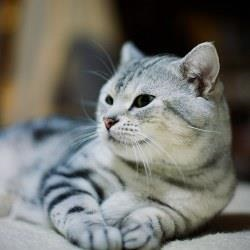

In [3]:
display.Image('cat.jpg')

In [4]:
resnet50=resnet.ResNet50(include_top=True,
             pretrained=True,
             input_shape=(3, 224, 224),
             classes=1000)

model file is already existing, donnot need download again.
25557032 parameters have set untrainable
2049000 parameters have set trainable
cuda:0
25557032 parameters have set untrainable
2049000 parameters have set trainable
cuda:0


In [5]:
resnet50.summary()

--------------------------------------------------------------------------------------------------------------------------------
               Layer (type)                Output Shape               Weight                            Bias      Param #   FLOPS #                  
first_block.conv  [Conv2d]                 [None, 64, 112, 112]       'weight', [64, 3, 7, 7]                     9,408  236,015,360  
first_block.norm  [BatchNorm]              [None, 64, 112, 112]       'weight', [64]                    'bias', [64]  128  3,186,176  
first_block.activation  [Relu]             [None, 64, 112, 112]                                                   0  0  
first_block  [Conv2d_Block]                [None, 64, 112, 112]                                                   0  0  
maxpool  [MaxPool2d]                       [None, 64, 56, 56]                                                     0  0  
layer1.0.branch1.0.conv  [Conv2d]          [None, 64, 56, 56]         'weight', [64, 64,

ImageClassificationModel()

In [6]:
print(resnet50.infer_single_image('cat.jpg',5))

{  n02124075	埃及猫: (285, 0.91520053),  n02128757	雪豹: (289, 0.056361903),  n02123045	虎斑猫: (281, 0.010579893),  n02123159	山猫: (282, 0.009001698),  n02127052	猞猁: (287, 0.004944114) }


In [16]:
data_provider=T.load_examples_data('animals')
data_provider.image_transform_funcs=[
                     RandomCenterCrop((224,224),scale_range=(0.8,2)),
                     #原比例隨機縮放(正確縮放比例再乘上0.8~1.2之間隨機數)中央裁切至224,224
                     RandomAdjustGamma(gamma_range=(0.6,1.5)),
                     #隨機調整圖片明暗gamma 0.6~1.4之間
                     RandomAdjustContrast(value_range=(0.6, 1.5)),
                     #隨機調整圖片對比度
                     RandomTransform(rotation_range=20,zoom_range=0.1,shift_range=0.02,shear_range=0.02,random_flip=0.2),
                     GrayMixRGB(keep_prob=0.75),
                     SaltPepperNoise(prob=0.002),#椒鹽噪音                 
                     RandomGridMask(size_range=(224,224),max_d1=64,rotation_range=(10,30),keep_prob=0.6),
                     Normalize(0,255),#除以255
                     Normalize([0.485, 0.456, 0.406],[0.229, 0.224, 0.225])] 

archive file is already existing, donnot need download again.
extraction is finished, donnot need extract again.
C:/Users/allan/.trident/datasets/examples_animals
['cat', 'chipmunk', 'dog', 'fox', 'giraffe', 'guinea pig', 'hyena', 'reindeer', 'sikadeer', 'squirrel', 'weasel', 'wolf']
C:/Users/allan/.trident/datasets/examples_animals/cat/*.*g
2766
C:/Users/allan/.trident/datasets/examples_animals/chipmunk/*.*g
2829
C:/Users/allan/.trident/datasets/examples_animals/dog/*.*g
3132
C:/Users/allan/.trident/datasets/examples_animals/fox/*.*g
3191
C:/Users/allan/.trident/datasets/examples_animals/giraffe/*.*g
3227
C:/Users/allan/.trident/datasets/examples_animals/guinea pig/*.*g
2970
C:/Users/allan/.trident/datasets/examples_animals/hyena/*.*g
2679
C:/Users/allan/.trident/datasets/examples_animals/reindeer/*.*g
3158
C:/Users/allan/.trident/datasets/examples_animals/sikadeer/*.*g
2857
C:/Users/allan/.trident/datasets/examples_animals/squirrel/*.*g
2551
C:/Users/allan/.trident/datasets/examples_

image


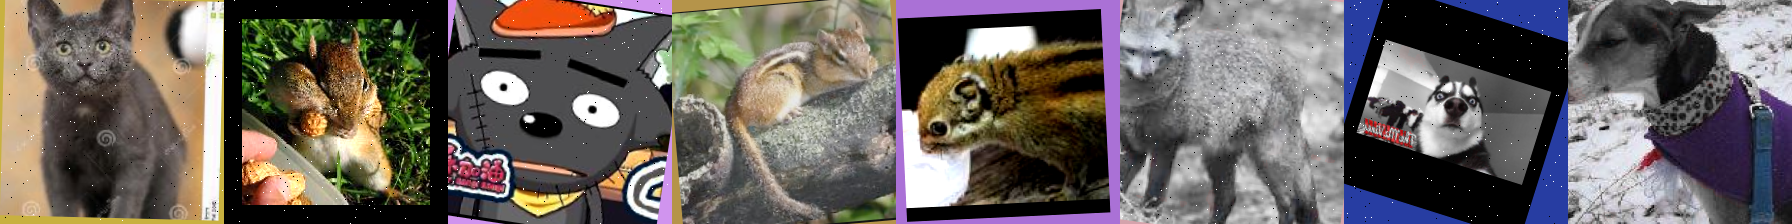

In [17]:
data_provider.preview_images()

In [18]:
images,labels=data_provider.next()
print(images.shape)

(8, 3, 224, 224)


In [19]:
resnet50=resnet.ResNet50(include_top=True,
             pretrained=True,
             input_shape=(3,224, 224),
             classes=12)


resnet50.with_optimizer(optimizer=AdaBelief,lr=1e-3,betas=(0.9, 0.999))\
    .with_loss(CrossEntropyLoss(auto_balance=True))\
    .with_metric(accuracy,name='accuracy')\
    .with_metric(accuracy,topk=3,name='top3_accuracy')\
    .with_regularizer('l2',reg_weight=1e-5)\
    .with_model_save_path('Models/finetune_resnet50.pth')\
    .with_learning_rate_scheduler(CosineLR(period=12000,unit='batch',max_lr=1e-3, min_lr=1e-6))\
    .with_automatic_mixed_precision_training()

model file is already existing, donnot need download again.
25557032 parameters have set untrainable
cuda:0
23532620 parameters have set untrainable
cuda:0
CrossEntropyLoss( output: Tensor[(None,)] , target: Tensor[(None,)] ) -> loss: Tensor[(None,)]  
CrossEntropyLoss SoftMax
accuracy( output: Tensor[(None,)] , target: Tensor[(None,)] , topk: int =1, axis: int =1, ignore_index: int =-100, exclude_mask: bool =False) -> output: Tensor[(None,)]  
top3_accuracy( output: Tensor[(None,)] , target: Tensor[(None,)] , topk: int =1, axis: int =1, ignore_index: int =-100, exclude_mask: bool =False) -> output: Tensor[(None,)]  
Automatic Mixed Precision:Turn On.


ImageClassificationModel(
  (_losses): <trident.optims.pytorch_losses.CrossEntropyLoss object at 0x000001332E29F748>
  (_metrics): <function accuracy at 0x000001329DE16158>
  (_metrics): functools.partial(<function accuracy at 0x000001329DE16158>, topk=3)
  (loss_weights): 1.0
  (_regs): <function l2_reg at 0x000001329DE10D08>
)

data_feed for resnet50 :
{
    "axis": "axis",
    "exclude_mask": "exclude_mask",
    "ignore_index": "ignore_index",
    "output": "output",
    "target": "label",
    "topk": "topk",
    "x": "image"
}
Start retrive label class distribution for auto-balance in loss function.


100%|████████████████████████████████████████████████████████████████████████| 35407/35407 [00:00<00:00, 765385.36it/s]

{ CrossEntropyLoss: 1.915, l2_reg_Loss: 3.978e-05, total_losses: 1.915 }
resnet50  Step: 759ms    | Loss: 1.897 | accuracy: 5.000% , top3_accuracy: 23.333%  | lr: 1.000e-03  | epoch: 0  ( 5/2951 )
resnet50  Step: 656ms    | Loss: 1.840 | accuracy: 6.667% , top3_accuracy: 23.333%  | lr: 1.000e-03  | epoch: 0  ( 10/2951 )
resnet50  Step: 571ms    | Loss: 1.814 | accuracy: 10.000% , top3_accuracy: 35.000%  | lr: 1.000e-03  | epoch: 0  ( 15/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   50°C   4% | 4521 /6144.0 MB  73.58%
resnet50  Step: 458ms    | Loss: 1.866 | accuracy: 3.333% , top3_accuracy: 26.667%  | lr: 1.000e-03  | epoch: 0  ( 20/2951 )
resnet50  Step: 270ms    | Loss: 1.875 | accuracy: 5.000% , top3_accuracy: 21.667%  | lr: 1.000e-03  | epoch: 0  ( 25/2951 )
resnet50  Step: 287ms    | Loss: 1.813 | accuracy: 10.000% , top3_accuracy: 31.667%  | lr: 1.000e-03  | epoch: 0  ( 30/2951 )
resnet50  Step: 306ms    | Loss: 1.815 | accuracy: 8.333% , top3_accuracy: 35.000%  | 

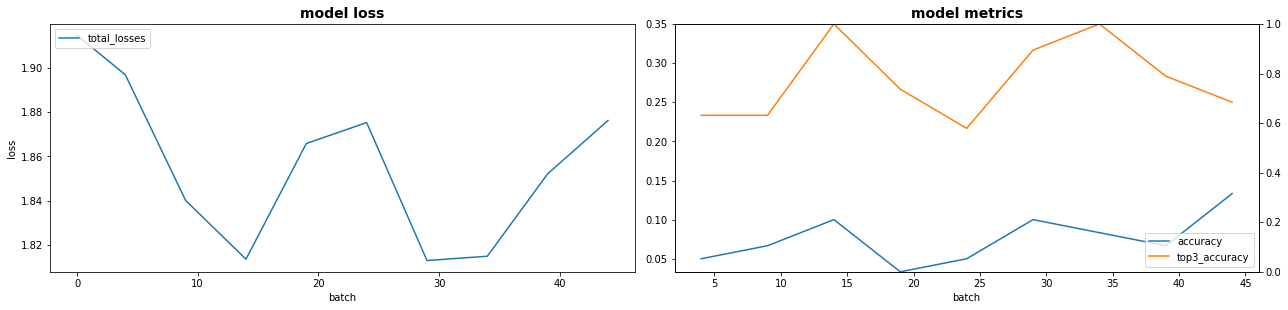

resnet50  Step: 564ms    | Loss: 1.840 | accuracy: 11.667% , top3_accuracy: 35.000%  | lr: 1.000e-03  | epoch: 0  ( 50/2951 )
resnet50  Step: 457ms    | Loss: 1.785 | accuracy: 20.000% , top3_accuracy: 31.667%  | lr: 1.000e-03  | epoch: 0  ( 55/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   51°C  19% | 4521 /6144.0 MB  73.58%
resnet50  Step: 521ms    | Loss: 1.849 | accuracy: 5.000% , top3_accuracy: 25.000%  | lr: 9.999e-04  | epoch: 0  ( 60/2951 )
resnet50  Step: 459ms    | Loss: 1.798 | accuracy: 13.333% , top3_accuracy: 38.333%  | lr: 9.999e-04  | epoch: 0  ( 65/2951 )
resnet50  Step: 436ms    | Loss: 1.783 | accuracy: 10.000% , top3_accuracy: 33.333%  | lr: 9.999e-04  | epoch: 0  ( 70/2951 )
resnet50  Step: 421ms    | Loss: 1.818 | accuracy: 8.333% , top3_accuracy: 21.667%  | lr: 9.999e-04  | epoch: 0  ( 75/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   52°C   7% | 4521 /6144.0 MB  73.58%
resnet50  Step: 333ms    | Loss: 1.837 | accuracy: 6.667% , top3_a

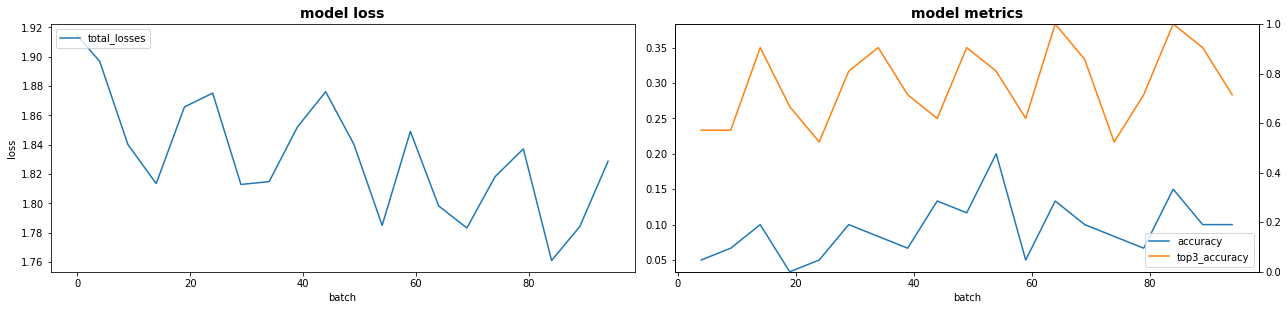

resnet50  Step: 418ms    | Loss: 1.791 | accuracy: 20.000% , top3_accuracy: 35.000%  | lr: 9.998e-04  | epoch: 0  ( 100/2951 )
resnet50  Step: 331ms    | Loss: 1.823 | accuracy: 8.333% , top3_accuracy: 28.333%  | lr: 9.998e-04  | epoch: 0  ( 105/2951 )
resnet50  Step: 277ms    | Loss: 1.784 | accuracy: 13.333% , top3_accuracy: 38.333%  | lr: 9.998e-04  | epoch: 0  ( 110/2951 )
resnet50  Step: 237ms    | Loss: 1.789 | accuracy: 16.667% , top3_accuracy: 35.000%  | lr: 9.998e-04  | epoch: 0  ( 115/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   55°C  16% | 2127 /6144.0 MB  34.62%
resnet50  Step: 298ms    | Loss: 1.762 | accuracy: 16.667% , top3_accuracy: 33.333%  | lr: 9.998e-04  | epoch: 0  ( 120/2951 )


In [ ]:
plan=TrainingPlan()\
    .add_training_item(resnet50)\
    .with_data_loader(data_provider)\
    .repeat_epochs(5)\
    .with_batch_size(12)\
    .print_progress_scheduling(5,unit='batch')\
    .print_gpu_utilization(20)\
    .save_model_scheduling(100,unit='batch')\
    .display_loss_metric_curve_scheduling(50,unit='batch',imshow=True)\
    .start_now()